# 🌡️ Küresel Sıcaklık Analizi ve Tahmini

*Global AI Hub × Akbank Makine Öğrenmesine Giriş Bootcamp'i projesinin gözden geçirilmiş sürümü.*

Veri: 1995–2020 arasında 125 ülkedeki 321 şehrin günlük ortalama sıcaklıkları.

Bu notebook iki soruyu ayrı ayrı cevaplıyor:

1. **Yakın geçmişi bilmeden** (yalnızca ülke, yıl, ay) günlük sıcaklığı ne kadar iyi tahmin edebiliriz?
2. **Dünkü ölçümleri bilerek** yarının sıcaklığını ne kadar iyi tahmin edebiliriz?

### İlk sürüme göre neler değişti?

| İlk sürüm | Bu sürüm |
|---|---|
| Eğitim/test rastgele bölündü; model test günlerinin öncesini ve sonrasını görmüştü | **Zamana dayalı bölme:** 1995–2015 eğitim, 2016–2019 test. Test seti yalnızca en sonda bir kez açıldı |
| Hedef °F, grafik eksenleri °C yazıyordu | Tüm analiz **°C** ile |
| Basit bir temel modelle kıyas yoktu | Klimatoloji ve "dün = bugün" (persistence) temel modelleri |
| Tek bir sayı (R²) raporlandı | Şehir düzeyinde **bootstrap %95 güven aralıkları** ve temel modele göre **eşleştirilmiş fark** |
| Hücreler sırasız çalışmıştı (`features` tanımlanmadan kullanılıyordu) | Notebook baştan sona, sırayla çalışır |

## 1. Kurulum

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
EGITIM_SON_YIL = 2015          # 1995–2015: eğitim
TEST_YILLARI = (2016, 2019)    # 2016–2019: kilitli test (2020 yalnızca Ocak–Mayıs olduğu için dışarıda)

## 2. Veri

Dataset: [Temperature of All Countries (1995–2020)](https://www.kaggle.com/datasets/subhamjain/temperature-of-all-countries-19952020). Zip dosyası doğrudan okunuyor; açmaya gerek yok.

In [2]:
ham = pd.read_csv("Veri Seti.zip", low_memory=False)
print(f"{len(ham):,} satır, {ham.Country.nunique()} ülke")
ham.head()

2,906,327 satır, 125 ülke


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Africa,Algeria,NaN,Algiers,1,1,1995,64.200
1,Africa,Algeria,NaN,Algiers,1,2,1995,49.400
2,Africa,Algeria,NaN,Algiers,1,3,1995,48.800
3,Africa,Algeria,NaN,Algiers,1,4,1995,46.400
4,Africa,Algeria,NaN,Algiers,1,5,1995,47.900


### Veri kalitesi

Temizlemeden önce sorunları sayalım: eksik ölçüm yer tutucusu `-99`, hatalı yıl değerleri (200, 201), `Day = 0` satırları ve aynı şehir-gün için tekrar eden kayıtlar.

In [3]:
anahtar = ["Country", "State", "City", "Year", "Month", "Day"]
sorunlar = pd.Series({
    "AvgTemperature = -99 (eksik)": (ham.AvgTemperature == -99).sum(),
    "Year < 1995 (hatalı yıl)": (ham.Year < 1995).sum(),
    "Day = 0": (ham.Day == 0).sum(),
    "Tekrarlanan şehir-gün": ham.duplicated(anahtar).sum(),
    "2020 (yalnızca Ocak–Mayıs)": (ham.Year == 2020).sum(),
})
sorunlar.to_frame("satır")

,satır
AvgTemperature = -99 (eksik),79672
Year < 1995 (hatalı yıl),440
Day = 0,8
Tekrarlanan şehir-gün,20968
2020 (yalnızca Ocak–Mayıs),38810


In [4]:
df = ham[(ham.AvgTemperature != -99) & (ham.Year >= 1995) & (ham.Day > 0) & (ham.Year <= 2019)].copy()
df = df.drop_duplicates(anahtar)
df["sehir"] = df.Country + " | " + df.State.fillna("") + " | " + df.City
df["tarih"] = pd.to_datetime(dict(year=df.Year, month=df.Month, day=df.Day), errors="coerce")
df = df.dropna(subset=["tarih"])
df["T"] = (df.AvgTemperature - 32) * 5 / 9          # °F → °C
df = df.sort_values(["sehir", "tarih"]).reset_index(drop=True)
print(f"Temizlik sonrası {len(df):,} ölçüm, {df.sehir.nunique()} şehir")
df["T"].describe()

Temizlik sonrası 2,767,848 ölçüm, 325 şehir


count   2,767,848.000
mean           15.823
std            10.615
min           -45.556
25%             8.667
50%            17.444
75%            24.444
max            43.333
Name: T, dtype: float64

## 3. Keşifçi analiz

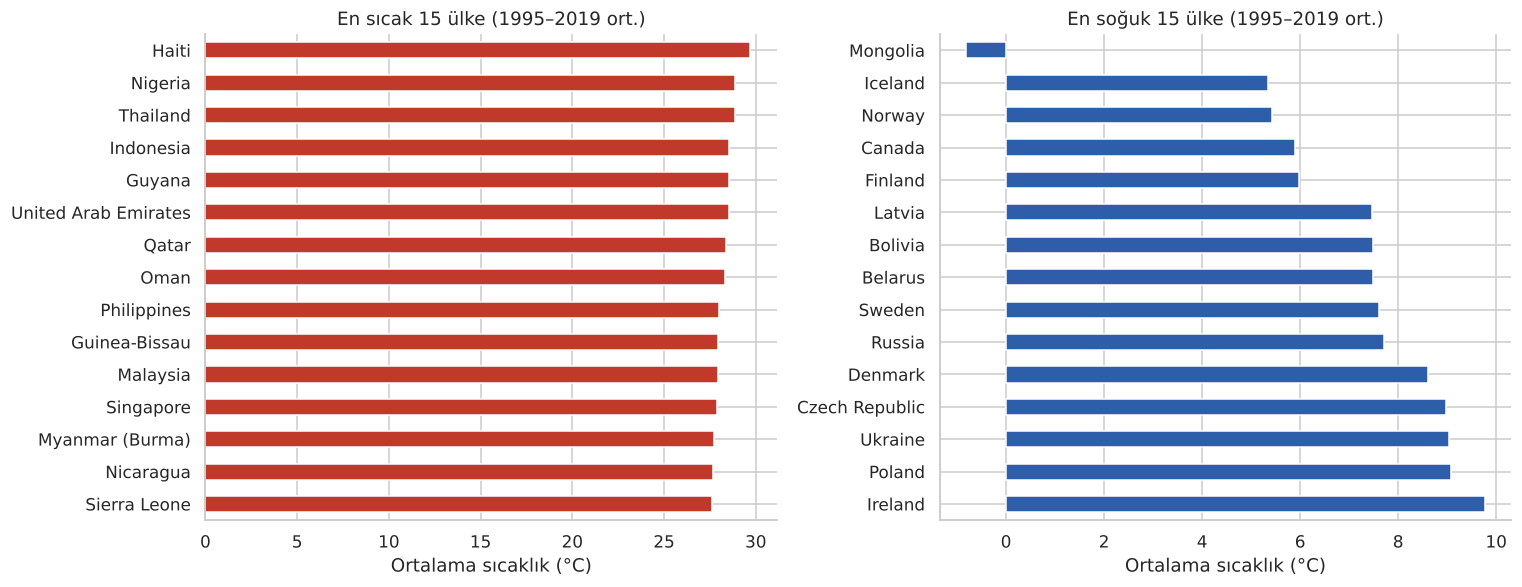

In [5]:
ulke = df.groupby("Country")["T"].mean().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ulke.tail(15).plot.barh(ax=ax[0], color="#C0392B"); ax[0].set_title("En sıcak 15 ülke (1995–2019 ort.)")
ulke.head(15)[::-1].plot.barh(ax=ax[1], color="#2E5EAA"); ax[1].set_title("En soğuk 15 ülke (1995–2019 ort.)")
for a in ax:
    a.set_xlabel("Ortalama sıcaklık (°C)"); a.set_ylabel("")
plt.tight_layout(); plt.show()

In [6]:
# Varyansın ne kadarı coğrafya + mevsimle açıklanıyor?
toplam = df["T"].var()
pay = pd.Series({
    "ülke × ay ortalaması": df.groupby(["Country", "Month"])["T"].transform("mean").var() / toplam,
    "şehir × ay ortalaması": df.groupby(["sehir", "Month"])["T"].transform("mean").var() / toplam,
})
pay.to_frame("açıklanan varyans payı")

,açıklanan varyans payı
ülke × ay ortalaması,0.728
şehir × ay ortalaması,0.872


Sıcaklığın büyük kısmı "nerede ve hangi ay" sorusuyla açıklanıyor. Kalan kısım günlük hava değişkenliği. Bu yüzden **yakın geçmişi kullanmayan bir model klimatolojiyi (o yerin o aydaki ortalamasını) geçmekte zorlanacak**. Bu beklentiyi aşağıda test ediyoruz.

## 4. Zamana dayalı bölme ve özellikler

- **Eğitim:** 1995–2015 · **Test:** 2016–2019
- Klimatoloji ortalamaları (şehir × ay, ülke × ay) **yalnızca eğitim yıllarından** hesaplanıyor; böylece test bilgisi modele sızmıyor.
- Gecikmeli özellikler yalnızca gerçekten bir önceki takvim gününe aitse kullanılıyor; eksik günlerin yerini başka bir gün almıyor.

In [7]:
g = df.groupby("sehir", sort=False)
for k in (1, 2, 3):
    onceki = g["T"].shift(k)
    gecerli = (df.tarih - g["tarih"].shift(k)).dt.days == k
    df[f"lag{k}"] = onceki.where(gecerli)

# Son 7 günün ortalaması (bugün hariç), yalnızca takvim günlerine göre
df = df.set_index("tarih")
df["ort7"] = (df.groupby("sehir")["T"]
                .transform(lambda s: s.rolling("7D", closed="left", min_periods=4).mean()))
df = df.reset_index()

egitim_mask = df.Year <= EGITIM_SON_YIL
test_mask = df.Year.between(*TEST_YILLARI)

def klimatoloji(veri, anahtarlar, ad):
    return veri.groupby(anahtarlar)["T"].mean().rename(ad)

def klimatoloji_ekle(hedef, kaynak):
    out = hedef.copy()
    for anah, ad in [(["sehir", "Month"], "klim_sehir"), (["Country", "Month"], "klim_ulke")]:
        out = out.drop(columns=ad, errors="ignore").join(klimatoloji(kaynak, anah, ad), on=anah)
    out["anomali_dun"] = out.lag1 - out.klim_sehir
    return out

df = klimatoloji_ekle(df, df[egitim_mask])
df["ay_sin"] = np.sin(2 * np.pi * df.tarih.dt.dayofyear / 365.25)
df["ay_cos"] = np.cos(2 * np.pi * df.tarih.dt.dayofyear / 365.25)
df["bolge"] = df.Region.astype("category").cat.codes
df["ulke_kod"] = df.Country.astype("category").cat.codes

egitim, test = df[egitim_mask], df[test_mask]
print(f"Eğitim: {len(egitim):,} satır · Test: {len(test):,} satır")

Eğitim: 2,347,770 satır · Test: 420,078 satır


## 5. Değerlendirme yardımcıları

Aynı şehrin günleri birbirinden bağımsız değil. Bu yüzden güven aralıklarını **şehir düzeyinde bootstrap** ile hesaplıyoruz: şehirleri yeniden örnekleyip MAE'yi 1.000 kez hesaplıyoruz. İki model kıyaslanırken aynı yeniden örneklemlerde **eşleştirilmiş fark** alınıyor.

In [8]:
rng = np.random.default_rng(SEED)

def metrikler(y, tahmin):
    return {"MAE (°C)": mean_absolute_error(y, tahmin),
            "RMSE (°C)": mean_squared_error(y, tahmin) ** 0.5,
            "R²": r2_score(y, tahmin)}

def sehir_bootstrap(veri, hata_sutunlari, B=1000):
    # Her yeniden örneklemde şehirler yerine koyarak seçilir; MAE = toplam |hata| / toplam gün.
    toplam = veri.groupby("sehir")[hata_sutunlari].agg(lambda s: s.abs().sum())
    adet = veri.groupby("sehir").size().to_numpy()
    idx = rng.integers(0, len(adet), size=(B, len(adet)))
    agirlik = np.zeros((B, len(adet)))
    np.add.at(agirlik, (np.repeat(np.arange(B), len(adet)), idx.ravel()), 1)
    return pd.DataFrame((agirlik @ toplam.to_numpy()) / (agirlik @ adet)[:, None], columns=hata_sutunlari)

def ga(x):
    return f"[{np.percentile(x, 2.5):.3f}, {np.percentile(x, 97.5):.3f}]"

## 6. Soru 1: Yakın geçmiş olmadan tahmin

İlk sürümdeki kurulum (`Year`, `Month`, `CountryEncoded` → Random Forest) zamana dayalı bölmede yeniden değerlendiriliyor ve iki klimatoloji temel modeliyle kıyaslanıyor. Hiperparametreler ilk sürümün ızgara aramasında seçilenler (`max_depth=20`, `min_samples_split=5`). Hızlı çalışması için her ağaç eğitim verisinin %20'siyle eğitiliyor.

In [9]:
ozellik_1 = ["Year", "Month", "ulke_kod"]
rf = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_split=5,
                           max_samples=0.2, n_jobs=-1, random_state=SEED)
rf.fit(egitim[ozellik_1], egitim["T"])

s1 = test[["sehir", "T"]].copy()
s1["Ülke × ay klimatolojisi"] = test.klim_ulke
s1["Random Forest (ilk sürüm kurulumu)"] = rf.predict(test[ozellik_1])
s1["Şehir × ay klimatolojisi"] = test.klim_sehir.fillna(test.klim_ulke)

modeller_1 = ["Ülke × ay klimatolojisi", "Random Forest (ilk sürüm kurulumu)", "Şehir × ay klimatolojisi"]
tablo_1 = pd.DataFrame({m: metrikler(s1["T"], s1[m]) for m in modeller_1}).T
hata_1 = s1[modeller_1].sub(s1["T"], axis=0).assign(sehir=s1.sehir)
boot_1 = sehir_bootstrap(hata_1, modeller_1)
tablo_1["MAE %95 GA"] = [ga(boot_1[m]) for m in modeller_1]
tablo_1

,MAE (°C),RMSE (°C),R²,MAE %95 GA
Ülke × ay klimatolojisi,3.975,5.546,0.723,"[3.731, 4.237]"
Random Forest (ilk sürüm kurulumu),4.140,5.753,0.702,"[3.905, 4.389]"
Şehir × ay klimatolojisi,2.796,3.843,0.867,"[2.668, 2.913]"


In [10]:
fark = boot_1["Random Forest (ilk sürüm kurulumu)"] - boot_1["Ülke × ay klimatolojisi"]
print(f"RF − ülke×ay klimatolojisi, MAE farkı: {fark.mean():+.3f} °C, %95 GA {ga(fark)}")

RF − ülke×ay klimatolojisi, MAE farkı: +0.166 °C, %95 GA [0.116, 0.215]


**Yorum.** İlk sürümdeki Random Forest esasen her ülkenin aylık ortalamasını öğreniyor ve zamana dayalı testte ülke × ay klimatolojisinden daha iyi değil; aksine biraz daha kötü (fark +0,17 °C, güven aralığı sıfırı içermiyor). Ağaçlar yıl değişkenine bakarak eğitim dönemine özgü dalgalanmaları öğreniyor ve bu, geleceğe taşınmıyor. Şehir bilgisini eklemek ise hatayı belirgin biçimde düşürüyor; çünkü aynı ülkedeki şehirlerin iklimi çok farklı olabiliyor (ör. ABD ve Rusya'da birden fazla şehir var).

## 7. Soru 2: Ertesi gün tahmini

Gerçek bir tahmin problemi: bugünün sıcaklığını, **dünkü ve önceki günlerin ölçümlerini** bilerek tahmin etmek.

- **Temel model (persistence):** bugün = dün
- **Model:** Histogram tabanlı gradient boosting. Özellikler: son 3 günün sıcaklığı, son 7 günün ortalaması, şehir ve ülke klimatolojisi, dünkü anomali, yılın günü (sin/cos), yıl ve bölge.

Hiperparametreler eğitim yılları içinde ayrılan bir doğrulama döneminde (eğitim 1995–2011, doğrulama 2012–2015) seçiliyor. Klimatoloji bu aşamada yalnızca 1995–2011'den yeniden hesaplanıyor. Test seti bu aşamada hiç kullanılmıyor.

In [11]:
ozellik_2 = ["lag1", "lag2", "lag3", "ort7", "klim_sehir", "klim_ulke", "anomali_dun",
             "ay_sin", "ay_cos", "Year", "bolge"]
tam = lambda d: d.dropna(subset=["lag1", "lag2", "lag3", "ort7", "klim_sehir"])

ic_egitim_ham = egitim[egitim.Year <= 2011]
ic_egitim = tam(klimatoloji_ekle(ic_egitim_ham, ic_egitim_ham))
dogrulama = tam(klimatoloji_ekle(egitim[egitim.Year.between(2012, 2015)], ic_egitim_ham))

izgara = [dict(learning_rate=lr, max_leaf_nodes=yp, min_samples_leaf=200)
          for lr in (0.05, 0.1) for yp in (31, 127)]
sonuc = []
for p in izgara:
    m = HistGradientBoostingRegressor(max_iter=400, early_stopping=False, random_state=SEED, **p)
    m.fit(ic_egitim[ozellik_2], ic_egitim["T"])
    sonuc.append({**p, "doğrulama MAE": mean_absolute_error(dogrulama["T"], m.predict(dogrulama[ozellik_2]))})
sonuc = pd.DataFrame(sonuc).sort_values("doğrulama MAE")
en_iyi = sonuc.iloc[0][["learning_rate", "max_leaf_nodes", "min_samples_leaf"]].to_dict()
en_iyi = {k: (int(v) if k != "learning_rate" else float(v)) for k, v in en_iyi.items()}
print("Seçilen:", en_iyi)
sonuc

Seçilen: {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'min_samples_leaf': 200}


,learning_rate,max_leaf_nodes,min_samples_leaf,doğrulama MAE
0,0.050,31,200,1.795
2,0.100,31,200,1.799
1,0.050,127,200,1.804
3,0.100,127,200,1.822


In [12]:
egitim2, test2 = tam(egitim), tam(test)
print(f"Gecikmeli özellikleri tam olan test günleri: {len(test2):,} / {len(test):,} (%{len(test2)/len(test)*100:.1f})")

hgb = HistGradientBoostingRegressor(max_iter=400, early_stopping=False, random_state=SEED, **en_iyi)
hgb.fit(egitim2[ozellik_2], egitim2["T"])

s2 = test2[["sehir", "Region", "Month", "T"]].copy()
s2["Şehir × ay klimatolojisi"] = test2.klim_sehir
s2["Persistence (bugün = dün)"] = test2.lag1
s2["Gradient boosting"] = hgb.predict(test2[ozellik_2])

modeller_2 = ["Şehir × ay klimatolojisi", "Persistence (bugün = dün)", "Gradient boosting"]
tablo_2 = pd.DataFrame({m: metrikler(s2["T"], s2[m]) for m in modeller_2}).T
hata_2 = s2[modeller_2].sub(s2["T"], axis=0).assign(sehir=s2.sehir)
boot_2 = sehir_bootstrap(hata_2, modeller_2)
tablo_2["MAE %95 GA"] = [ga(boot_2[m]) for m in modeller_2]
tablo_2

Gecikmeli özellikleri tam olan test günleri: 414,281 / 420,078 (%98.6)


,MAE (°C),RMSE (°C),R²,MAE %95 GA
Şehir × ay klimatolojisi,2.805,3.854,0.866,"[2.688, 2.935]"
Persistence (bugün = dün),1.924,2.783,0.930,"[1.840, 2.011]"
Gradient boosting,1.787,2.536,0.942,"[1.711, 1.867]"


In [13]:
fark2 = boot_2["Gradient boosting"] - boot_2["Persistence (bugün = dün)"]
print(f"Gradient boosting − persistence, MAE farkı: {fark2.mean():+.3f} °C, %95 GA {ga(fark2)}")
iyilesme = 1 - tablo_2.loc["Gradient boosting", "MAE (°C)"] / tablo_2.loc["Persistence (bugün = dün)", "MAE (°C)"]
print(f"Persistence'a göre MAE iyileşmesi: %{iyilesme*100:.1f}")

Gradient boosting − persistence, MAE farkı: -0.137 °C, %95 GA [-0.147, -0.128]
Persistence'a göre MAE iyileşmesi: %7.1


## 8. Sonuçların görselleştirilmesi

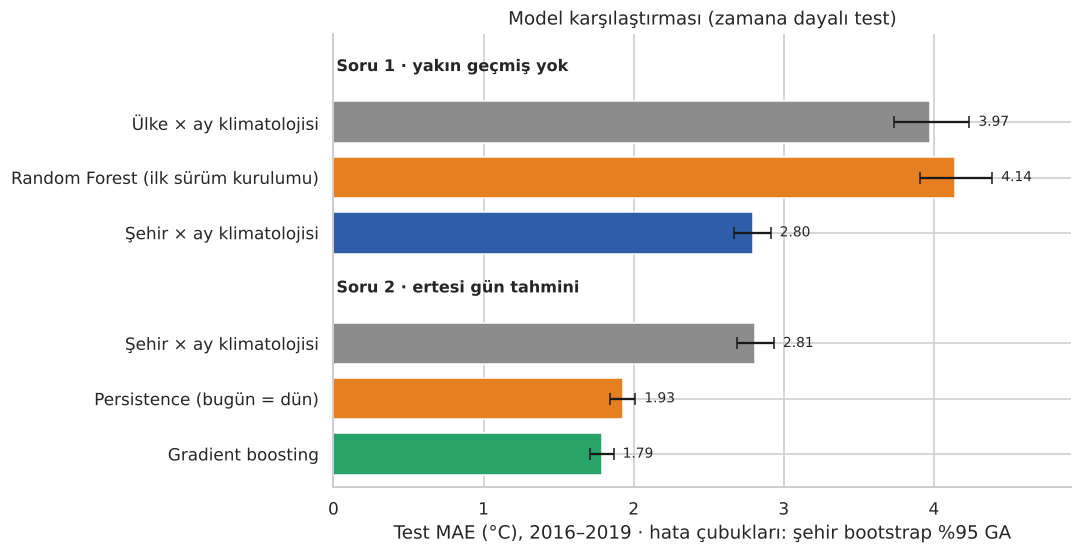

In [14]:
ozet = pd.concat([
    pd.DataFrame({"model": modeller_1, "soru": "Soru 1: yakın geçmiş yok"}),
    pd.DataFrame({"model": modeller_2, "soru": "Soru 2: ertesi gün"}),
])
ozet["MAE"] = [boot_1[m].mean() for m in modeller_1] + [boot_2[m].mean() for m in modeller_2]
ozet["alt"] = [np.percentile(boot_1[m], 2.5) for m in modeller_1] + [np.percentile(boot_2[m], 2.5) for m in modeller_2]
ozet["ust"] = [np.percentile(boot_1[m], 97.5) for m in modeller_1] + [np.percentile(boot_2[m], 97.5) for m in modeller_2]

fig, ax = plt.subplots(figsize=(10, 5.2))
renk = ["#8C8C8C", "#E67E22", "#2E5EAA", "#8C8C8C", "#E67E22", "#29A36A"]
y = np.array([7, 6, 5, 3, 2, 1])
ax.barh(y, ozet.MAE, xerr=[ozet.MAE - ozet.alt, ozet.ust - ozet.MAE], color=renk, capsize=4, height=0.75)
ax.set_yticks(y, list(ozet.model))
for yi, v, u in zip(y, ozet.MAE, ozet.ust):
    ax.text(u + 0.06, yi, f"{v:.2f}", va="center", fontsize=9)
for yi, baslik in [(8, "Soru 1 · yakın geçmiş yok"), (4, "Soru 2 · ertesi gün tahmini")]:
    ax.text(0.02, yi, baslik, va="center", fontsize=10.5, weight="bold")
ax.set_ylim(0.4, 8.6); ax.set_xlim(0, ozet.ust.max() * 1.12)
ax.set_xlabel("Test MAE (°C), 2016–2019 · hata çubukları: şehir bootstrap %95 GA")
ax.set_title("Model karşılaştırması (zamana dayalı test)")
plt.tight_layout(); fig.savefig("images/03_model_karsilastirma.png", bbox_inches="tight", facecolor="white"); plt.show()

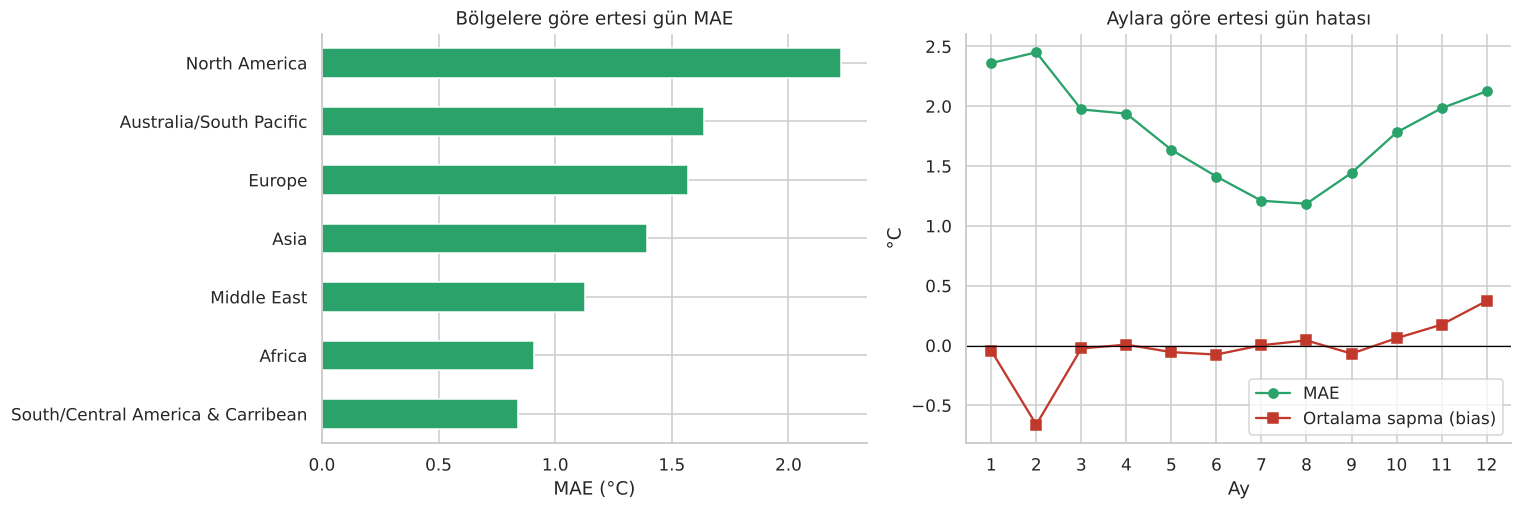

In [15]:
s2["hata"] = s2["Gradient boosting"] - s2["T"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
(s2.groupby("Region").hata.apply(lambda e: e.abs().mean()).sort_values()
   .plot.barh(ax=ax[0], color="#29A36A"))
ax[0].set_title("Bölgelere göre ertesi gün MAE"); ax[0].set_xlabel("MAE (°C)"); ax[0].set_ylabel("")
aylik = s2.groupby("Month").hata.agg(MAE=lambda e: e.abs().mean(), sapma="mean")
ax[1].plot(aylik.index, aylik.MAE, marker="o", color="#29A36A", label="MAE")
ax[1].plot(aylik.index, aylik.sapma, marker="s", color="#C0392B", label="Ortalama sapma (bias)")
ax[1].axhline(0, color="black", lw=0.8); ax[1].set_xticks(range(1, 13))
ax[1].set_title("Aylara göre ertesi gün hatası"); ax[1].set_xlabel("Ay"); ax[1].set_ylabel("°C"); ax[1].legend()
plt.tight_layout(); fig.savefig("images/04_hata_analizi.png", bbox_inches="tight", facecolor="white"); plt.show()

## 9. Sonuçlar

1. **İlk sürümün R² = 0,73 sonucu bir enterpolasyondu.** Rastgele bölmede model test günlerinin öncesini ve sonrasını görmüştü. Zamana dayalı bölmede aynı kurulum (MAE 4,14 °C), ülkenin aylık ortalamasından (3,97 °C) daha iyi değil, biraz daha kötü.
2. **Coğrafi ayrıntı önemli.** Ülke yerine şehir klimatolojisi kullanmak, yakın geçmiş olmadan da MAE'yi 3,97'den 2,80 °C'ye düşürüyor.
3. **Ertesi gün tahmininde asıl bilgi dünkü ölçümde.** "Bugün = dün" kuralı zaten güçlü bir temel model. Bu kural MAE'yi 1,92 °C'ye indiriyor. Gradient boosting, son günlerin ölçümlerini klimatolojiyle birleştirerek 1,79 °C'ye iniyor (%7 iyileşme; eşleştirilmiş fark −0,14 °C, %95 GA [−0,15; −0,13]).
4. **Belirsizlik raporlanmalı.** Aynı şehrin günleri bağımsız olmadığı için güven aralıkları şehir düzeyinde hesaplandı; satır düzeyinde hesaplansaydı yapay olarak dar çıkardı.

### Sınırlılıklar

- Veride yalnızca ortalama sıcaklık var; yağış, nem, rüzgâr gibi değişkenlerle tahmin iyileşebilir.
- Şehir örneklemi ABD ağırlıklı; bölge sonuçları bu dengesizliği yansıtıyor.
- Klimatoloji 1995–2015 ortalaması. Isınma eğilimi nedeniyle test döneminde klimatoloji hafif soğuk tarafta kalabilir; bunu düzeltmek için modelde yıl değişkeni var.